# FUTON Solvers

FUTON with a linear decoder is the paper's model: a basis along each axis, a CP
combiner and a linear decoder, both without bias, with an optional activation at
the output. On a grid its output is a CP tensor, linear in each factor matrix
and in the decoder when the others are held, so every block is a least-squares
problem whose two sides are small, and the model can be fitted by block
coordinate descent rather than by gradient descent. `nf.LeastSquares` solves
each block exactly, for any basis, and handles an output activation by refitting
Gauss-Newton targets every sweep; `nf.MultiplicativeUpdate` takes Lee and
Seung's step instead, which keeps a nonnegative model nonnegative. Both are
optimizers that `nf.train` takes in place of Adam, and both compile their
sweeps with `torch.compile`.

This notebook fits the linear FUTON to one Kodak image, kodim19, three ways:
with Adam, FUTON (linear, Adam); by alternating least squares, FUTON (linear,
ALS); and, with hat functions, by multiplicative updates, FUTON (linear, MU).
All run at the image benchmark's grid and parameter budget, next to the
benchmark's model, whose decoder is a one-layer MLP, trained by Adam: FUTON
(MLP, Adam).

## Setup

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from matplotlib.ticker import (
    FixedLocator,
    MaxNLocator,
    MultipleLocator,
    NullFormatter,
    StrMethodFormatter,
)
from matplotlib_inline.backend_inline import set_matplotlib_formats

import neurofield as nf

set_matplotlib_formats("retina")  # sharp figures on high-resolution screens
sns.set_theme(
    context="notebook", style="whitegrid", font_scale=0.85, rc={"grid.color": ".92"}
)

# The benchmark's model in black, and the three ways to fit the linear one.
PALETTE = dict(
    zip(
        (
            "FUTON (MLP, Adam)",
            "FUTON (linear, Adam)",
            "FUTON (linear, ALS)",
            "FUTON (linear, MU)",
        ),
        ("black", *sns.color_palette("colorblind", 3)),
    )
)
DASHES = {model: "" for model in PALETTE}

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")

Device: cuda


The plotting helpers: training time on a log axis, the metric on whole
decibels or half points, a summary table, images side by side, and
reconstructions above their errors.

In [2]:
NICE = [1, 2, 5, 10]  # tick steps: 1, 2 or 5 times a power of ten


def time_axis(ax, times):
    """Training time on a log axis, ticked 1, 2, 5, 10, ... in plain numbers."""
    low, high = times.min() / 1.1, times.max() * 1.1
    ax.set(xscale="log", xlim=(low, high), xlabel="Training time (s)")
    for subs in ((1, 2, 5), (1,)):
        ticks = [m * 10.0**k for k in range(-3, 6) for m in subs]
        ticks = [tick for tick in ticks if low <= tick <= high]
        if len(ticks) <= 7:
            break
    ax.xaxis.set_major_locator(FixedLocator(ticks))
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}"))
    ax.xaxis.set_minor_formatter(NullFormatter())


def metric_axis(ax, metric, low, high):
    """The metric's axis over [low, high]: whole decibels for a PSNR, half
    points for an IoU, which cannot pass 100."""
    if metric == "IoU (%)":
        low = np.floor(2 * low) / 2
        ax.set_ylim(low, min(max(np.ceil(2 * high) / 2, low + 0.5), 100))
        ax.yaxis.set_major_locator(MultipleLocator(0.5))
    else:
        low = np.floor(low)
        ax.set_ylim(low, max(np.ceil(high), low + 1))
        ax.yaxis.set_major_locator(MaxNLocator(nbins=6, steps=NICE, integer=True))


def table(summary, formats, better):
    """The summary, each column in its format and, in each column of
    ``better`` ("higher" or "lower"), the best value bold and the second
    underlined."""

    def marks(column):
        rank = column.rank(method="min", ascending=better[column.name] == "lower")
        looks = {1: "font-weight: bold", 2: "text-decoration: underline"}
        return [looks.get(r, "") for r in rank]

    return (
        summary.style.format(formats, na_rep="")
        .apply(marks, subset=list(better))
        .hide(axis="index")
    )


def show(panels, ncols, width=11, **imshow):
    """Images side by side under their titles, in rows of ``ncols``, each
    drawn at the size of the first."""
    height, side = panels[0][1].shape[:2]
    nrows = -(-len(panels) // ncols)
    room = 0.45 if any("\n" in title for title, _ in panels) else 0.3
    fig, axes = plt.subplots(
        nrows,
        ncols,
        squeeze=False,
        layout="constrained",
        figsize=(width, nrows * (width / ncols * height / side + room)),
    )
    for ax in axes.flat:
        ax.axis("off")
    for ax, (title, image) in zip(axes.flat, panels):
        ax.imshow(image, interpolation="nearest", **imshow)
        ax.set_title(title, fontsize=9)
    return fig


def compare(panels, label, width=11):
    """The reference and the reconstructions in a row under their titles
    (``panels``, the reference first), and beneath each reconstruction its
    absolute error, averaged over the colour channels; the errors share one
    scale, which saturates at their 99th percentile, and its colour bar
    stands beneath the reference."""
    reference = panels[0][1].astype(float)
    errors = [np.abs(image - reference).mean(-1) for _, image in panels[1:]]
    height, side = reference.shape[:2]
    ncols = len(panels)
    fig, axes = plt.subplots(
        2,
        ncols,
        layout="constrained",
        figsize=(width, 2 * width / ncols * height / side + 0.45),
    )
    for ax in axes.flat:
        ax.axis("off")
    for ax, (title, image) in zip(axes[0], panels):
        ax.imshow(image, interpolation="nearest")
        ax.set_title(title, fontsize=9)
    vmax = np.percentile(np.concatenate([error.ravel() for error in errors]), 99)
    for ax, error in zip(axes[1, 1:], errors):
        maps = ax.imshow(
            error, cmap="magma", vmin=0, vmax=vmax, interpolation="nearest"
        )
    bar = fig.colorbar(maps, cax=axes[1, 0].inset_axes([0.8, 0.04, 0.07, 0.92]))
    bar.ax.yaxis.set_ticks_position("left")
    bar.ax.yaxis.set_label_position("left")
    bar.ax.yaxis.set_major_locator(MaxNLocator(nbins=4, steps=NICE))
    bar.ax.tick_params(labelsize=8)
    bar.set_label(label, fontsize=9)
    bar.outline.set_visible(False)
    return fig

## Data

The image, 768 by 512 pixels, and the region that the comparison magnifies.

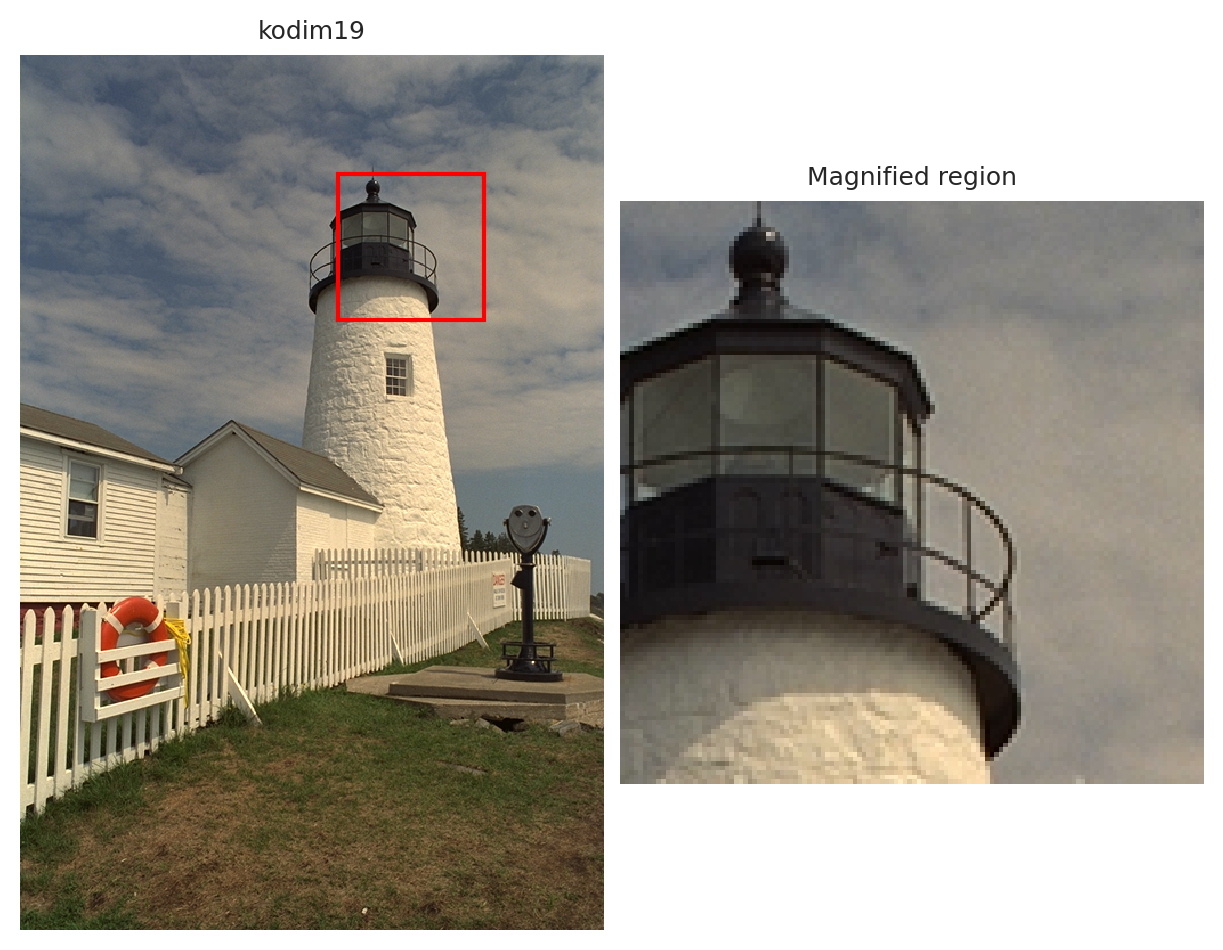

In [3]:
IMAGE_PATH = "../data/Kodak/kodim19.png"
CROP = (slice(104, 232), slice(279, 407))  # rows and columns: the lighthouse's lantern

image = nf.ImageCoordinateDataset(IMAGE_PATH)  # every pixel, for evaluation
H, W = image.grid_size
original = image.original.permute(1, 2, 0).numpy()  # (H, W, 3), uint8

fig = show(
    [("kodim19", original), ("Magnified region", original[CROP])], ncols=2, width=6
)
rows, columns = CROP
box = plt.Rectangle(
    (columns.start, rows.start), columns.stop - columns.start, rows.stop - rows.start
)
fig.axes[0].add_patch(box).set(fill=False, edgecolor="red", linewidth=1.5)
plt.show()

## Models

Every model has `(H/2, W/2)` basis functions per axis, the benchmark's grid, and
about 194k parameters. FUTON (MLP, Adam) is the benchmark's model, at CP rank 252
under a one-layer MLP decoder 128 wide; the linear models spend its decoder's
33k parameters on rank instead, 301. FUTON (linear, Adam) has a sinc basis and a
tanh at the output, and Adam trains it as the benchmark trains its model: 2000
steps, each on a random 10% of the pixels, at learning rate 3e-2. FUTON
(linear, ALS) is the same model fitted by alternating least squares. FUTON
(linear, MU) has hat functions, nonnegative and left unnormalized so that they
sum to one, and an affine output activation that maps its nonnegative output
onto the signal's range; multiplicative updates fit it.

The solvers sweep the whole image instead, 500 times each: least squares solves
every block's problem exactly, and multiplicative updates, which converge more
slowly, repeat each block's update 16 times a sweep, their default. A sweep
works on the image's grid, whatever share of its pixels the batch holds, so a
sweep over the whole image costs about what one over a tenth does, and its
blocks' problems are the whole image's rather than a sample's. Each sweep can
then stand on its own, `momentum=0`. A solver's `momentum` averages each block's
problem over the batches, as minibatches need, and `nf.train` anneals the
newest batch's weight, `1 - momentum`, as it does Adam's learning rate, so that
even without momentum the later sweeps average the earlier ones as the model
settles.

In [4]:
COMPONENTS = (H // 2, W // 2)
RANK = 252  # the benchmark's CP rank, under its one-layer MLP decoder of width 128


def signed(z):
    """From [0, 1] to [-1, 1]: the output activation of a nonnegative model."""
    return 2 * z - 1


def futon(basis, decoder, rank, output_activation=torch.tanh, **basis_kwargs):
    return {
        "basis": (  # on the pixels
            basis,
            {"num_components": COMPONENTS, "grid_size": (H, W), **basis_kwargs},
        ),
        "combiner": ("cp", {"rank": rank}),
        "decoder": decoder,
        "output_activation": output_activation,
    }


def adam(model):
    return torch.optim.Adam(model.parameters(), lr=3e-2)


MLP = ("mlp", {"hidden_layers": 1, "hidden_features": 128})
LINEAR = ("linear", {"bias": False})  # the paper's decoder
BUDGET = nf.count_parameters(nf.FUTON(2, 3, **futon("sinc", MLP, RANK)))
# A linear decoder holds 3 R weights and a factor K_c R, so the rank that
# spends the budget on the grid is BUDGET / (K_1 + K_2 + 3).
LINEAR_RANK = BUDGET // (sum(COMPONENTS) + 3)

CONFIGS = [
    {  # the benchmark's model, trained as the benchmark trains it
        "name": "FUTON (MLP, Adam)",
        "kwargs": futon("sinc", MLP, RANK),
        "optimizer": adam,
        "epochs": 2000,
        "subsample": 0.1,  # the share of the pixels in a batch
    },
    {  # the paper's model, a CP model in the sinc basis, trained by Adam
        "name": "FUTON (linear, Adam)",
        "kwargs": futon("sinc", LINEAR, LINEAR_RANK),
        "optimizer": adam,
        "epochs": 2000,
        "subsample": 0.1,
    },
    {  # the same model, fitted by least squares on the whole image
        "name": "FUTON (linear, ALS)",
        "kwargs": futon("sinc", LINEAR, LINEAR_RANK),
        "optimizer": lambda model: nf.LeastSquares(model, momentum=0),
        "epochs": 500,
        "subsample": 1.0,
    },
    {  # a nonnegative model, fitted by multiplicative updates on the whole image
        "name": "FUTON (linear, MU)",
        "kwargs": futon("triangle", LINEAR, LINEAR_RANK, signed, normalize=False),
        "optimizer": lambda model: nf.MultiplicativeUpdate(model, momentum=0),
        "epochs": 500,
        "subsample": 1.0,
    },
]
print(f"Budget {BUDGET:,}: rank {LINEAR_RANK} for the linear models")

METRICS = {"psnr": nf.psnr, "ssim": nf.ssim, "lpips": nf.lpips}

Budget 194,051: rank 301 for the linear models


## Training

One call trains every model, with its own optimizer: Adam, whose learning rate
`nf.train` anneals, or a solver, which has none. Every model is compiled with
`torch.compile`, and before training starts an untimed forward and backward pass
compiles it, or for a solver `optimizer.compile(batch)`, which runs one untimed
sweep and leaves the model and the solver as they were. Twenty times in a run
the model is evaluated on the whole image. The training times exclude the
compilation and the evaluations.

In [5]:
results, fitted = {}, {}

for config in CONFIGS:
    torch.manual_seed(0)
    train_dataset = nf.ImageCoordinateDataset(IMAGE_PATH, subsample=config["subsample"])
    model = nf.FUTON(in_features=2, out_features=3, **config["kwargs"])
    print(f"{config['name']}: {nf.count_parameters(model):,} parameters")
    model.to(device).compile()
    sample = train_dataset[0]
    batch = {key: sample[key][None].to(device) for key in ("input", "target")}
    optimizer = config["optimizer"](model)
    if isinstance(optimizer, nf.BCD):
        optimizer.compile(batch)  # compiles the sweep
    else:
        model(batch["input"]).sum().backward()  # compiles the model
        model.zero_grad(set_to_none=True)
    result = nf.train(
        model,
        train_dataset,
        image,
        optimizer=optimizer,
        num_epochs=config["epochs"],
        metrics=METRICS,
        log_interval=config["epochs"] // 20,
        eval_interval=config["epochs"] // 20,
        device=device,
    )
    output = nf.chunked_inference(model, image.input, device=device)
    result["reconstruction"] = image.postprocess(output.cpu()).permute(1, 2, 0).numpy()
    results[config["name"]], fitted[config["name"]] = result, model

    del result["model_dict"]
    torch.cuda.empty_cache()
    torch.compiler.reset()  # the next model compiles anew

FUTON (MLP, Adam): 194,051 parameters
FUTON (linear, Adam): 193,543 parameters
FUTON (linear, ALS): 193,543 parameters
FUTON (linear, MU): 193,543 parameters


## Convergence

The PSNR of the whole image, twenty times in a run. A step is an Adam step on a
random 10% of the pixels or a solver's sweep over the whole image.

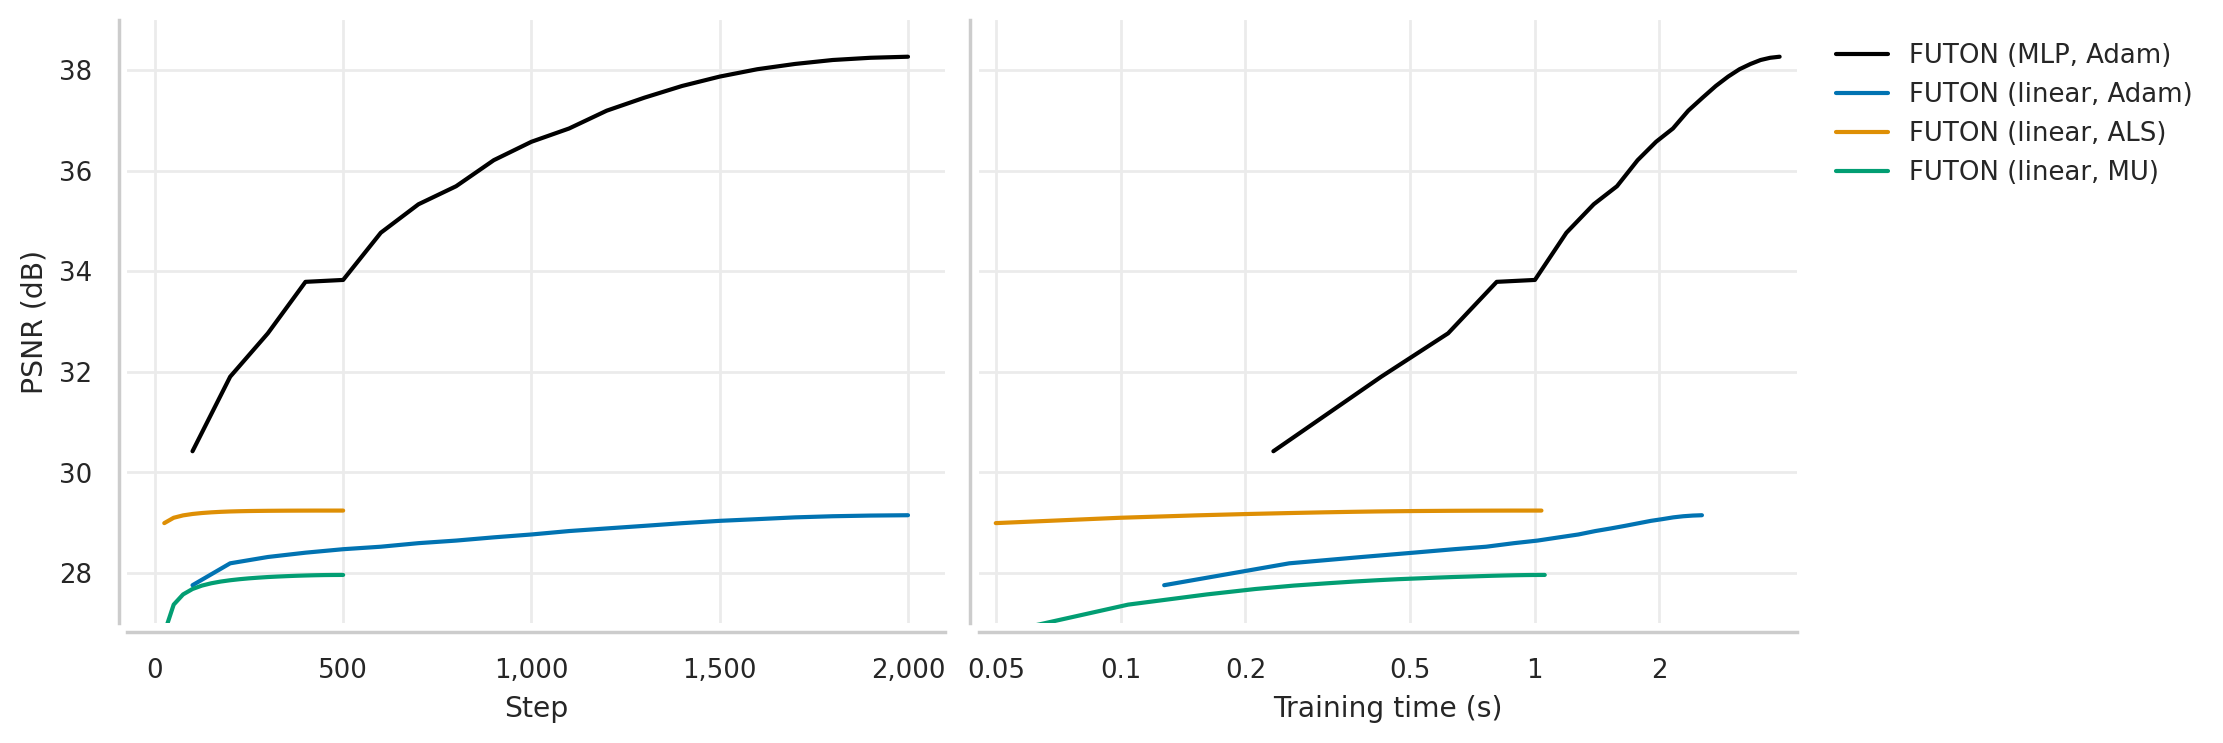

In [6]:
records = pd.DataFrame(
    {
        "Model": name,
        "Step": entry["epoch"],
        "Time (s)": entry["elapsed"],
        "PSNR (dB)": entry["eval"]["psnr"],
    }
    for name, result in results.items()
    for entry in result["history"]
    if "eval" in entry
)

order = [model for model in PALETTE if model in set(records["Model"])]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True, layout="constrained")
for ax, x in zip(axes, ("Step", "Time (s)")):
    sns.lineplot(
        records,
        x=x,
        y="PSNR (dB)",
        hue="Model",
        style="Model",
        hue_order=order,
        style_order=order,
        palette=PALETTE,
        dashes=DASHES,
        legend=ax is axes[1],
        ax=ax,
    )
axes[0].xaxis.set_major_locator(MaxNLocator(nbins=5, steps=NICE))
axes[0].xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
final = records.groupby("Model")["PSNR (dB)"].last()
low, high = final.min(), records["PSNR (dB)"].max()
margin = 0.05 * (high - low)  # so that no curve ends on the frame
metric_axis(axes[0], "PSNR (dB)", low - margin, high + margin)
shown = records["PSNR (dB)"] >= axes[0].get_ylim()[0]  # the evaluations in view
time_axis(axes[1], records.loc[shown, "Time (s)"])

sns.move_legend(
    axes[-1], "upper left", bbox_to_anchor=(1.02, 1), title=None, frameon=False
)
sns.despine(fig, offset=3)
plt.show()

## Summary

The solvers change how a model trains, not how it renders, so the table gives the
training costs: the time, and the most memory a step allocated. In each column
the best value is bold and the second underlined.

In [7]:
rows = []
for name, result in results.items():
    final = result["history"][-1]["eval"]
    rows.append(
        {
            "Model": name,
            "Params (k)": result["config"]["num_params"] / 1e3,
            "Training time (s)": result["history"][-1]["elapsed"],
            "Training memory (MB)": result["config"]["peak_memory"] / 1e6,
            "PSNR (dB)": final["psnr"],
            "SSIM": final["ssim"],
            "LPIPS": final["lpips"],
        }
    )
summary = pd.DataFrame(rows).sort_values("PSNR (dB)", ascending=False)
formats = {
    "Params (k)": "{:.1f}",
    "Training time (s)": "{:.2f}",
    "Training memory (MB)": "{:.0f}",
    "PSNR (dB)": "{:.2f}",
    "SSIM": "{:.3f}",
    "LPIPS": "{:.3f}",
}
better = {
    "Training time (s)": "lower",
    "Training memory (MB)": "lower",
    "PSNR (dB)": "higher",
    "SSIM": "higher",
    "LPIPS": "lower",
}
table(summary, formats, better)

Model,Params (k),Training time (s),Training memory (MB),PSNR (dB),SSIM,LPIPS
"FUTON (MLP, Adam)",194.1,3.91,104,38.26,0.956,0.103
"FUTON (linear, ALS)",193.5,1.04,35,29.24,0.864,0.207
"FUTON (linear, Adam)",193.5,2.54,54,29.15,0.862,0.219
"FUTON (linear, MU)",193.5,1.06,46,27.96,0.838,0.246


In [8]:
adam, als = (
    records[records["Model"] == f"FUTON (linear, {n})"] for n in ("Adam", "ALS")
)
target = adam["PSNR (dB)"].iloc[-1]
passed = als[als["PSNR (dB)"] >= target].iloc[0]
sooner = adam["Time (s)"].iloc[-1] / passed["Time (s)"]
print(
    f"Least squares passes Adam's final {target:.2f} dB after {passed['Step']} "
    f"sweeps, in {passed['Time (s)']:.2f} s, {sooner:.0f} times sooner than Adam."
)

Least squares passes Adam's final 29.15 dB after 100 sweeps, in 0.20 s, 12 times sooner than Adam.


On the same model, least squares ends above Adam, in less time and with less
memory, and passes Adam's final PSNR early in its run: every sweep solves each
block's problem for the whole image, at the cost of a few products on its grid
and one Cholesky factorization a block, the basis's side of each problem being
fixed and inverted once. On minibatches, momentum is what lets a solver learn
instead: solved from a single tenth of the image, a block would chase that
tenth's noise, and the averaged problem is the whole image's. The nonnegative
hat-basis model, fitted by multiplicative updates, ends below least squares.
The MLP decoder is what separates the benchmark's FUTON from all three linear
models.

## Qualitative Comparison

The magnified region of every reconstruction, titled with its PSNR on the whole
image, and beneath, the error of each, averaged over the colour channels, on
one scale.

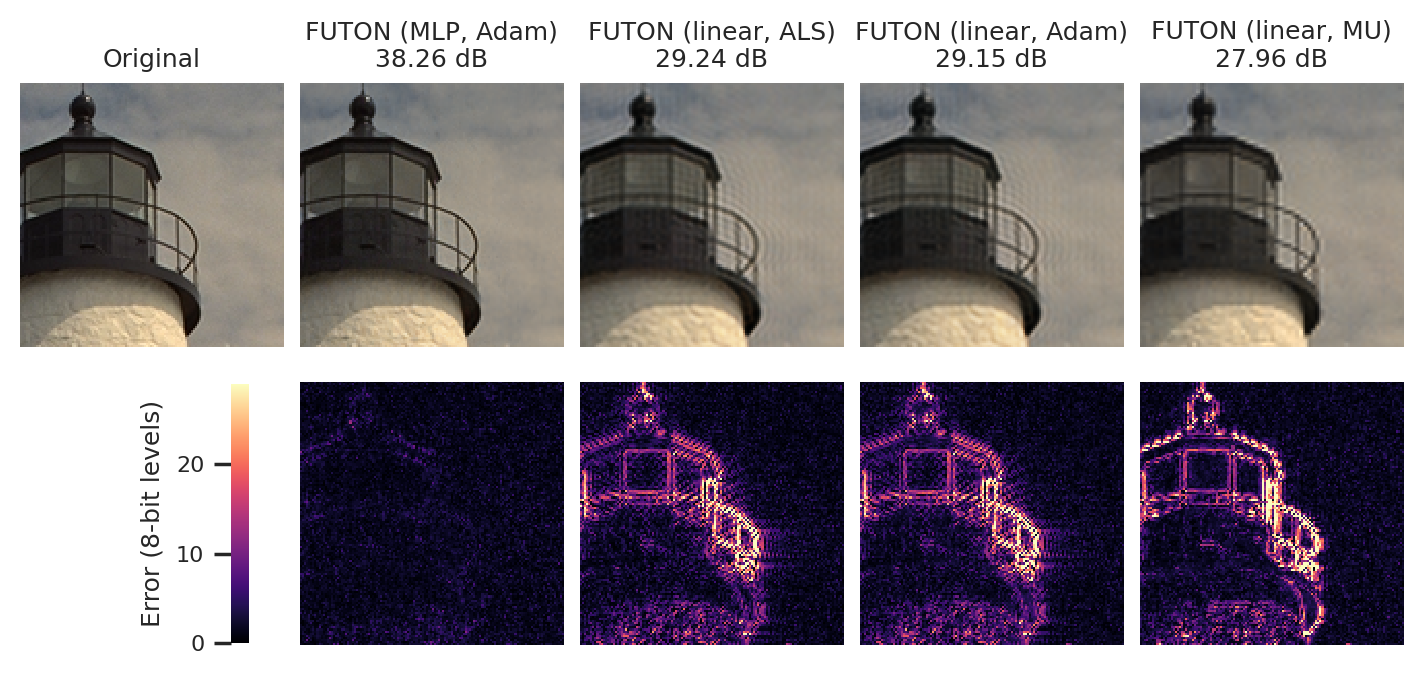

In [9]:
crops = [("Original", original[CROP])] + [
    (f"{name}\n{psnr:.2f} dB", results[name]["reconstruction"][CROP])
    for name, psnr in zip(summary["Model"], summary["PSNR (dB)"])
]
compare(crops, "Error (8-bit levels)", width=7)
plt.show()

## Nonnegative Parts

With a linear decoder, the output is a sum over the rank of products of one
response per axis, each scaled by the decoder's column for that component. In
the nonnegative model every term is a nonnegative rank-one image, a part, and
the image is their sum, which the affine output activation maps onto the
signal's range. Below are the eight parts of FUTON (linear, MU) that
contribute the most, each on its own scale, which saturates at its 99.5th
percentile.

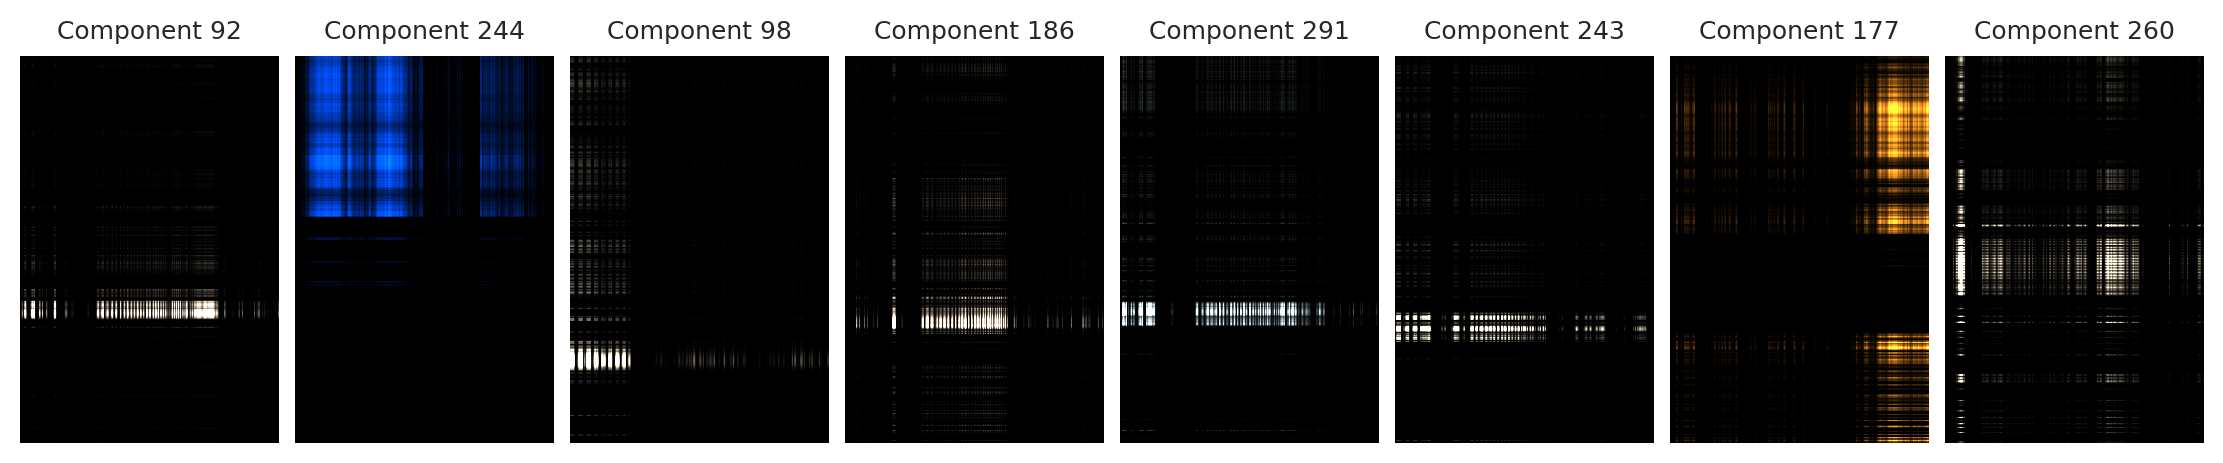

In [10]:
model = fitted["FUTON (linear, MU)"]
with torch.no_grad():
    x = image.input.to(device)  # (H, W, 2) grid coordinates
    rows, columns = x[:, 0, 0], x[0, :, 1]
    basis, combiner = model.encoding.basis, model.encoding.combiner
    responses = [
        basis.axis_features(u, c) @ factor
        for c, (u, factor) in enumerate(zip((rows, columns), combiner.factors))
    ]
    weight = model.decoder.weight  # (3, R)
    strength = responses[0].sum(0) * responses[1].sum(0) * weight.sum(0)
    chosen = strength.topk(8).indices
    parts = torch.einsum(
        "hr,wr,dr->rhwd",
        responses[0][:, chosen],
        responses[1][:, chosen],
        weight[:, chosen],
    )

show(
    [
        (f"Component {i}", (part / part.quantile(0.995)).clamp(max=1).cpu().numpy())
        for i, part in zip(chosen.tolist(), parts)
    ],
    ncols=8,
)
plt.show()